In [1]:
import pandas as pd
print ("Python marsh!")
print ("Pandas version:", pd.__version__)


Python marsh!
Pandas version: 2.2.2


In [2]:
import os
os.listdir()

['.ipynb_checkpoints',
 '01_Beaute_Cachee_Data_Profiling.ipynb',
 '02_Sales_CRM_Analysis.ipynb']

In [3]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\igrav\Desktop\Mariia\CRM Project 1\02_Notebooks
['.ipynb_checkpoints', '01_Beaute_Cachee_Data_Profiling.ipynb', '02_Sales_CRM_Analysis.ipynb']


In [4]:
df = pd.read_csv(
    "../01_Data/raw/Womens Clothing E-Commerce Reviews.csv"
)

df.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [5]:
# Dimensions du dataset
print("Dimensions :", df.shape)

# Informations générales
df.info()

Dimensions : (23486, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB


In [6]:
# Nombre de valeurs manquantes par colonne
df.isnull().sum()

Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

In [7]:
# Pourcentage de valeurs manquantes
(df.isnull().sum() / len(df) * 100).round(2)

Unnamed: 0                  0.00
Clothing ID                 0.00
Age                         0.00
Title                      16.22
Review Text                 3.60
Rating                      0.00
Recommended IND             0.00
Positive Feedback Count     0.00
Division Name               0.06
Department Name             0.06
Class Name                  0.06
dtype: float64

In [8]:
# Data Quality Report
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing Count",
    ascending=False
)

missing_report

,Missing Count,Missing %
Title,3810,16.22
Review Text,845,3.60
Division Name,14,0.06
Department Name,14,0.06
Class Name,14,0.06
Unnamed: 0,0,0.00
Clothing ID,0,0.00
Age,0,0.00
Rating,0,0.00
Recommended IND,0,0.00


In [9]:
# Reviews without both title and text
df[
    df["Title"].isnull() &
    df["Review Text"].isnull()
].shape[0]

844

In [10]:
# Records with missing product categories
df[
    df["Division Name"].isnull()
][
    ["Clothing ID", "Rating", "Review Text",
     "Division Name", "Department Name", "Class Name"]
]

,Clothing ID,Rating,Review Text,Division Name,Department Name,Class Name
9444,72,5,"I never write reviews, but these socks are so ...",NaN,NaN,NaN
13767,492,5,I just love this hoodie! it is so soft and com...,NaN,NaN,NaN
13768,492,5,Love this hoodie. so soft and goes with everyt...,NaN,NaN,NaN
13787,492,5,NaN,NaN,NaN,NaN
16216,152,5,"Just what i was looking for. soft, cozy and warm.",NaN,NaN,NaN
16221,152,5,I am loving these. they are quite long but are...,NaN,NaN,NaN
16223,152,5,These leg warmers are perfect for me. they are...,NaN,NaN,NaN
18626,184,5,"These are amazing quality. i agree, size up to...",NaN,NaN,NaN
18671,184,5,These tights are amazing! if i care for them w...,NaN,NaN,NaN
20088,772,5,This sweatshirt is really nice! it's oversize...,NaN,NaN,NaN


In [11]:
# Check other records for Clothing ID = 492

df[
    df["Clothing ID"] == 492
][
    ["Clothing ID", "Division Name",
     "Department Name", "Class Name"]
].drop_duplicates()

,Clothing ID,Division Name,Department Name,Class Name
13767,492,NaN,NaN,NaN


In [12]:
# Get Clothing IDs with missing Division Name
missing_ids = df.loc[
    df["Division Name"].isnull(),
    "Clothing ID"
].unique()

# Find all records for these products
df_check = df[
    df["Clothing ID"].isin(missing_ids)
]

# Show unique category combinations
df_check[
    ["Clothing ID", "Division Name",
     "Department Name", "Class Name"]
].drop_duplicates().sort_values("Clothing ID")

,Clothing ID,Division Name,Department Name,Class Name
9444,72,NaN,NaN,NaN
22997,136,NaN,NaN,NaN
16216,152,NaN,NaN,NaN
18626,184,NaN,NaN,NaN
13767,492,NaN,NaN,NaN
21532,665,NaN,NaN,NaN
20088,772,NaN,NaN,NaN


In [13]:
# Check exact duplicate rows
df.duplicated().sum()

0

In [14]:
# Check duplicate reviews using selected columns
df.duplicated(
    subset=["Clothing ID", "Review Text", "Rating"]
).sum()

476

In [15]:
# Check duplicate rows excluding technical index
df.drop(columns=["Unnamed: 0"], errors="ignore").duplicated().sum()

21

In [16]:
# Check missing or empty review texts
df["Review Text"].fillna("").str.strip().eq("").sum()

845

In [17]:
# Select rows with non-empty review texts
valid_reviews = df["Review Text"].notna() & (
    df["Review Text"].str.strip() != ""
)

# Count potential duplicate reviews
df.loc[valid_reviews].duplicated(
    subset=["Clothing ID", "Review Text", "Rating"]
).sum()

2

In [18]:
# Identify exact duplicates excluding technical index
business_cols = df.columns.drop(
    "Unnamed: 0", errors="ignore"
).tolist()

exact_duplicates = df[
    df.duplicated(subset=business_cols, keep=False)
]

display(exact_duplicates.head(12))

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
298,298,1104,39,NaN,NaN,5,1,0,General,Dresses,Dresses
493,493,1104,39,NaN,NaN,5,1,0,General,Dresses,Dresses
1004,1004,1094,30,NaN,NaN,5,1,0,General,Dresses,Dresses
2739,2739,1094,36,NaN,NaN,5,1,0,General Petite,Dresses,Dresses
2941,2941,829,66,NaN,NaN,5,1,0,General Petite,Tops,Blouses
2959,2959,1094,30,NaN,NaN,5,1,0,General,Dresses,Dresses
3961,3961,895,36,NaN,NaN,5,1,0,General Petite,Tops,Fine gauge
3976,3976,1078,35,NaN,NaN,5,1,0,General,Dresses,Dresses
4850,4850,829,66,NaN,NaN,5,1,0,General Petite,Tops,Blouses
4866,4866,834,70,NaN,NaN,5,1,0,General Petite,Tops,Blouses


In [19]:
# Inspect duplicate reviews with non-empty text
review_cols = ["Clothing ID", "Review Text", "Rating"]

duplicate_reviews = df.loc[valid_reviews]

duplicate_reviews = duplicate_reviews[
    duplicate_reviews.duplicated(
        subset=review_cols,
        keep=False
    )
]

display(duplicate_reviews)

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
1891,1891,1081,42,"Beautiful dress, fits poorly",I purchased this and another eva franco dress ...,2,0,5,General,Dresses,Dresses
9447,9447,1022,37,NaN,"Love, love these jeans. being short they come ...",5,1,0,General,Bottoms,Jeans
12526,12526,1081,42,"Beautiful dress, fits horribly",I purchased this and another eva franco dress ...,2,0,3,General,Dresses,Dresses
21888,21888,1022,37,NaN,"Love, love these jeans. being short they come ...",5,1,0,General,Bottoms,Jeans


In [20]:
# Check exact duplicates with non-empty review text
df.loc[valid_reviews].duplicated(
    subset=business_cols
).sum()

1

In [21]:
# Display duplicate reviews without truncating text
pd.set_option("display.max_colwidth", None)

display(
    duplicate_reviews.sort_values(
        by=["Clothing ID", "Rating"]
    )
)

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
9447,9447,1022,37,NaN,"Love, love these jeans. being short they come right to my ankle. super soft and don?t require any hemming. i ordered my typical jean size of 26 and they fit like a glove. would love to have these in black and grey.",5,1,0,General,Bottoms,Jeans
21888,21888,1022,37,NaN,"Love, love these jeans. being short they come right to my ankle. super soft and don?t require any hemming. i ordered my typical jean size of 26 and they fit like a glove. would love to have these in black and grey.",5,1,0,General,Bottoms,Jeans
1891,1891,1081,42,"Beautiful dress, fits poorly","I purchased this and another eva franco dress during retailer's recent 20% off sale. i was looking for dresses that were work appropriate, but that would also transition well to happy hour or date night. they both seemed to be just what i was looking for. i ordered a 4 regular and a 6 regular, as i am usually in between sizes. the 4 was definitely too small. the 6 fit, technically, but was very ill fitting. not only is the dress itself short, but it is very short-waisted. i am only 5'3"", but it fe",2,0,5,General,Dresses,Dresses
12526,12526,1081,42,"Beautiful dress, fits horribly","I purchased this and another eva franco dress during retailer's recent 20% off sale. i was looking for dresses that were work appropriate, but that would also transition well to happy hour or date night. they both seemed to be just what i was looking for. i ordered a 4 regular and a 6 regular, as i am usually in between sizes. the 4 was definitely too small. the 6 fit, technically, but was very ill fitting. not only is the dress itself short, but it is very short-waisted. i am only 5'3"", but it fe",2,0,3,General,Dresses,Dresses


In [22]:
# Create a working copy for data cleaning
df_clean = df.copy()

# Remove the identified exact duplicate review
df_clean = df_clean.drop(index=21888)

# Verify the result
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Original rows: 23486
Cleaned rows: 23485
Rows removed: 1


In [23]:
# Remove one confirmed content duplicate by source index
df_clean = df.loc[df["Unnamed: 0"] != 21888].copy()

In [24]:
# Check Rating distribution
df_clean["Rating"].value_counts(dropna=False).sort_index()

Rating
1      842
2     1565
3     2871
4     5077
5    13130
Name: count, dtype: int64

In [25]:
# Check recommendation indicator
df_clean["Recommended IND"].value_counts(dropna=False)

Recommended IND
1    19313
0     4172
Name: count, dtype: int64

In [26]:
# Check customer age statistics
df_clean["Age"].describe()

count    23485.000000
mean        43.198808
std         12.279738
min         18.000000
25%         34.000000
50%         41.000000
75%         52.000000
max         99.000000
Name: Age, dtype: float64

In [27]:
# Inspect potentially unusual ages
df_clean.loc[
    df_clean["Age"] > 85, "Age"
].value_counts().sort_index()

Age
86    2
87    4
89    5
90    2
91    5
92    1
93    2
94    3
99    2
Name: count, dtype: int64

In [28]:
# Check positive feedback statistics
df_clean["Positive Feedback Count"].describe()

count    23485.000000
mean         2.536044
std          5.702299
min          0.000000
25%          0.000000
50%          1.000000
75%          3.000000
max        122.000000
Name: Positive Feedback Count, dtype: float64

In [29]:
# Top 5 reviews by positive feedback
df_clean[
    ["Clothing ID", "Rating", "Review Text", "Positive Feedback Count"]
].sort_values(
    by="Positive Feedback Count",
    ascending=False
).head(5)

,Clothing ID,Rating,Review Text,Positive Feedback Count
7218,1092,3,"I loved the lace detailing all over this dress and the fact it had pockets and was mostly cotton. it just looked so inviting, so i grabbed two sizes to try on (10 & 12) that 99% of the time fit me with retailer clothes. here are my thoughts:\n__________\npros:\n- lace detailing is lovely all over.\n- everything runs tts except at the bust (see below).\n- breathable fabric, comfortable.\n_________\ncons:\n- i'm a 36c and could not button the top two buttons of this dress in a size 10 (i'm 5'9, hourglass, a",122
1294,1095,5,"I've been on the hunt for the perfect dress to wear for my daughter's first birthday party. since we are throwing a traditional korean first birthday, i was looking for a dress you might wear to a daytime wedding or a fancy brunch. i just purchased this dress today in the store and it fits my needs perfectly. \r\n\r\ni disagree with the first reviewer who mentioned that this dress was too sheer. this dress is a thicker fabric so i do not think i will need a slip when wearing it. it does drape nicely",117
7765,986,1,"I generally don't write bad reviews, but there is a real discrepancy between the quality of this kimono and the cost. the design and colors are great, but the fabric is ripping on all the kimonos on the rack in my store where the manufacturer's tag is at the back of the neck. the material is very thin, so there are other small holes beginning throughout the garment. i shop at retailer all the time, and this is not a $98 item of clothing.",108
19094,1121,5,"I am a big fan of trench coats and i love that this one is navy. i typically gravitate toward blues because it brings out my eyes and my wardrobe tends to fall in a blue-ish category. i love that the color of this coat will compliment other pieces of clothing in my closet wonderfully.\n\ni especially love the design of the trench with the wider, pleated bottom which allows for fluffier dresses but also creates an illusion that is slimming for anyone's figure. this is a fantastic, unique design for",99
13210,1078,5,"This is my favorite dress i've bought in the past year! it is super flattering and can be worn for work or casual wear. the fabric is soft and comfortable. can't wait till the weather gets warmer so i can start wearing it regularly!\n\ni'm 5'5 145lbs, 37-29-39. i got the medium petite and it fits perfectly!",98


In [30]:
# Check categorical variables
categorical_cols = [
    "Division Name",
    "Department Name",
    "Class Name"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False))


--- Division Name ---
Division Name
General           13849
General Petite     8120
Initmates          1502
NaN                  14
Name: count, dtype: int64

--- Department Name ---
Department Name
Tops        10468
Dresses      6319
Bottoms      3798
Intimate     1735
Jackets      1032
Trend         119
NaN            14
Name: count, dtype: int64

--- Class Name ---
Class Name
Dresses           6319
Knits             4843
Blouses           3097
Sweaters          1428
Pants             1388
Jeans             1146
Fine gauge        1100
Skirts             945
Jackets            704
Lounge             691
Swim               350
Outerwear          328
Shorts             317
Sleep              228
Legwear            165
Intimates          154
Layering           146
Trend              119
NaN                 14
Casual bottoms       2
Chemises             1
Name: count, dtype: int64


In [31]:
# Inspect rows with missing product categories
df_clean.loc[
    df_clean["Division Name"].isna()
    | df_clean["Department Name"].isna()
    | df_clean["Class Name"].isna(),
    [
        "Clothing ID",
        "Division Name",
        "Department Name",
        "Class Name",
        "Rating"
    ]
]

,Clothing ID,Division Name,Department Name,Class Name,Rating
9444,72,NaN,NaN,NaN,5
13767,492,NaN,NaN,NaN,5
13768,492,NaN,NaN,NaN,5
13787,492,NaN,NaN,NaN,5
16216,152,NaN,NaN,NaN,5
16221,152,NaN,NaN,NaN,5
16223,152,NaN,NaN,NaN,5
18626,184,NaN,NaN,NaN,5
18671,184,NaN,NaN,NaN,5
20088,772,NaN,NaN,NaN,5


In [32]:
# Check mapping between Class Name and Department Name
pd.crosstab(
    df_clean["Class Name"],
    df_clean["Department Name"]
)

Department Name,Bottoms,Dresses,Intimate,Jackets,Tops,Trend
Class Name,,,,,,
Blouses,0,0,0,0,3097,0
Casual bottoms,2,0,0,0,0,0
Chemises,0,0,1,0,0,0
Dresses,0,6319,0,0,0,0
Fine gauge,0,0,0,0,1100,0
Intimates,0,0,154,0,0,0
Jackets,0,0,0,704,0,0
Jeans,1146,0,0,0,0,0
Knits,0,0,0,0,4843,0


# Jalon 1 — Validation de la qualité et du nettoyage des données

Statut : Terminé

Projet : Beauté Cachée — Analyse de l'expérience client

Jeu de données : Women's E-Commerce Clothing Reviews

## Bilan des contrôles

23 486 observations initiales

23 485 observations après nettoyage

1 avis strictement identique supprimé dans la copie analytique

Valeurs manquantes analysées et documentées

Cohérence des variables numériques vérifiée

Cohérence de la classification des produits vérifiée

Jeu de données brut conservé sans modification

## Décisions principales

Les avis sans commentaire textuel sont conservés pour les analyses quantitatives.

Les 14 observations sans catégorie de produit sont conservées pour les indicateurs globaux.

Les valeurs inhabituelles mais plausibles concernant l'âge et les votes utiles sont conservées.

Les doublons non confirmés sont conservés afin d'éviter toute suppression injustifiée.

## Conclusion :
Le jeu de données est prêt pour l'analyse exploratoire, sous réserve des limites de qualité identifiées et documentées.

# Jalon 2  — Analyse exploratoire des données (EDA)

## Objectif

Analyser les évaluations, les recommandations et les commentaires des clientes afin d'identifier les points forts, les axes d'amélioration et les opportunités d'optimisation de l'expérience client de Beauté Cachée.

## Questions d'analyse

Q01 — Satisfaction client par département

Quels départements de produits obtiennent les meilleures et les moins bonnes évaluations ?

Q02 — Recommandation des produits

Comment le taux de recommandation varie-t-il selon les départements de produits ?

Q03 — Cohérence entre évaluation et recommandation

Dans quelle mesure les notes attribuées aux produits correspondent-elles aux recommandations des clientes ?

Q04 — Segmentation des clientes

Comment les évaluations et les recommandations varient-elles selon les tranches d'âge ?

Q05 — Analyse des commentaires clients

Quels sont les thèmes récurrents, les motifs de satisfaction et les principales insatisfactions exprimés dans les avis ?



## Première analyse — Q01

Satisfaction client par département

### Indicateurs étudiés :

Nombre d'avis (Review Count)

Note moyenne (Average Rating)

Taux de recommandation (Recommendation Rate)

### Dimension d'analyse : 
Department Name

### Résultat attendu : 
Identifier les départements les mieux évalués et ceux nécessitant une analyse approfondie.

## Méthode de restitution

Pour chaque question d'analyse, documenter :

Résultats clés : principaux constats chiffrés.

Interprétation métier : implications pour l'expérience client.

Pistes d'action : investigations complémentaires ou recommandations opérationnelles.

In [33]:
# Q01 — Customer satisfaction by department

department_analysis = (
    df_clean.groupby("Department Name")
    .agg(
        Review_Count=("Rating", "count"),
        Average_Rating=("Rating", "mean"),
        Recommendation_Rate=("Recommended IND", "mean")
    )
    .reset_index()
)

# Convert recommendation rate to percentage
department_analysis["Recommendation_Rate"] *= 100

# Round KPI values
department_analysis = department_analysis.round(2)

# Sort departments by average rating
department_analysis = department_analysis.sort_values(
    by="Average_Rating",
    ascending=False
)

display(department_analysis)

,Department Name,Review_Count,Average_Rating,Recommendation_Rate
0,Bottoms,3798,4.29,85.12
2,Intimate,1735,4.28,85.01
3,Jackets,1032,4.26,83.62
4,Tops,10468,4.17,81.52
1,Dresses,6319,4.15,80.82
5,Trend,119,3.82,73.95


# Q01 — Premiers résultats

## Résultats clés

Le département Bottoms présente la note moyenne la plus élevée (4,29/5) et le meilleur taux de recommandation (85,12 %).

Les départements Intimate (4,28/5) et Jackets (4,26/5) obtiennent également de bons résultats.

Dresses enregistre une note moyenne de 4,15/5 sur 6 319 avis, ce qui justifie une analyse plus approfondie.

Trend affiche les indicateurs les plus faibles (3,82/5 ; 73,95 % de recommandation), mais ne compte que 119 avis.

## Interprétation métier

Les résultats suggèrent une satisfaction globalement favorable, avec des différences entre les départements. Les catégories Dresses et Trend méritent une attention particulière, sans conclure à ce stade à des causes précises d'insatisfaction.

## Prochaine étape

Examiner la répartition des notes et les avis négatifs afin de mieux comprendre les écarts observés.

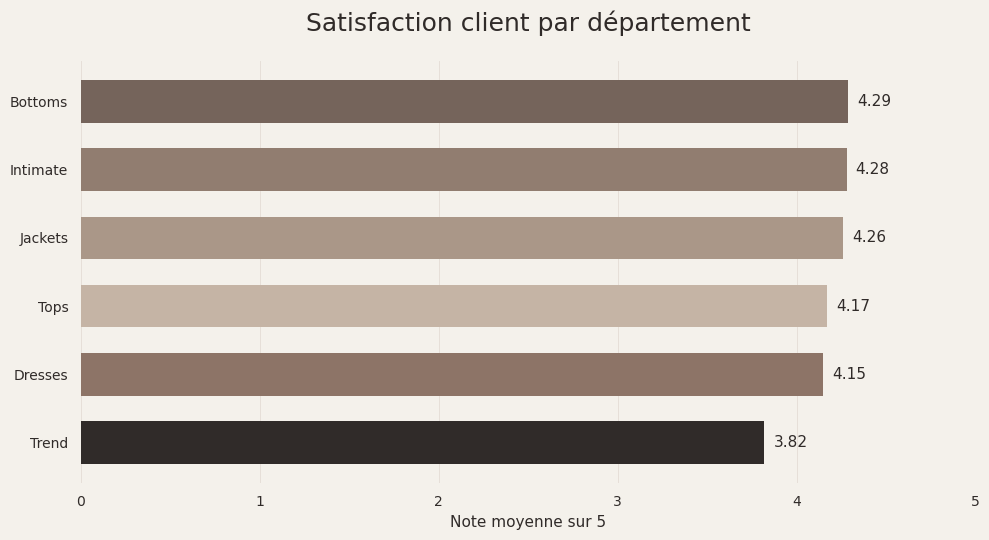

In [34]:
# Q01 — Satisfaction client par département
# Beauté Cachée | Luxury Editorial Style

import matplotlib.pyplot as plt

# Brand palette
ivory = "#F4F1EB"
charcoal = "#302B29"

department_colors = {
    "Bottoms": "#75645B",
    "Intimate": "#917D70",
    "Jackets": "#AA9788",
    "Tops": "#C5B4A5",
    "Dresses": "#8D7467",
    "Trend": "#302B29"
}

fig, ax = plt.subplots(figsize=(10, 5.5))

fig.patch.set_facecolor(ivory)
ax.set_facecolor(ivory)

colors = [
    department_colors[dept]
    for dept in department_analysis["Department Name"]
]

bars = ax.barh(
    department_analysis["Department Name"],
    department_analysis["Average_Rating"],
    color=colors,
    height=0.62
)

# Value labels
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        color=charcoal,
        fontsize=11
    )

ax.set_xlim(0, 5)
ax.invert_yaxis()

ax.set_title(
    "Satisfaction client par département",
    fontsize=18,
    color=charcoal,
    pad=22
)

ax.set_xlabel(
    "Note moyenne sur 5",
    fontsize=11,
    color=charcoal
)

ax.tick_params(
    axis="both",
    colors=charcoal,
    length=0,
    pad=9
)

ax.grid(
    axis="x",
    color="#DAD1C9",
    alpha=0.55,
    linewidth=0.7
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

### Étape 2 — Analyse de la répartition des notes

**Objectif :** Comparer la distribution des notes des départements
Dresses et Trend afin de mieux comprendre leurs résultats
de satisfaction client.

**Méthode :** Analyse de la part des notes de 1 à 5 étoiles
dans chaque département.

In [35]:
# Q01 — Step 2: Rating distribution by department

rating_distribution = pd.crosstab(
    df_clean["Department Name"],
    df_clean["Rating"],
    normalize="index"
) * 100

# Compare Dresses and Trend
comparison = rating_distribution.loc[
    ["Dresses", "Trend"]
].round(2)

display(comparison)

Rating,1,2,3,4,5
Department Name,,,,,
Dresses,3.61,7.30,13.26,22.08,53.76
Trend,9.24,9.24,15.97,21.85,43.70


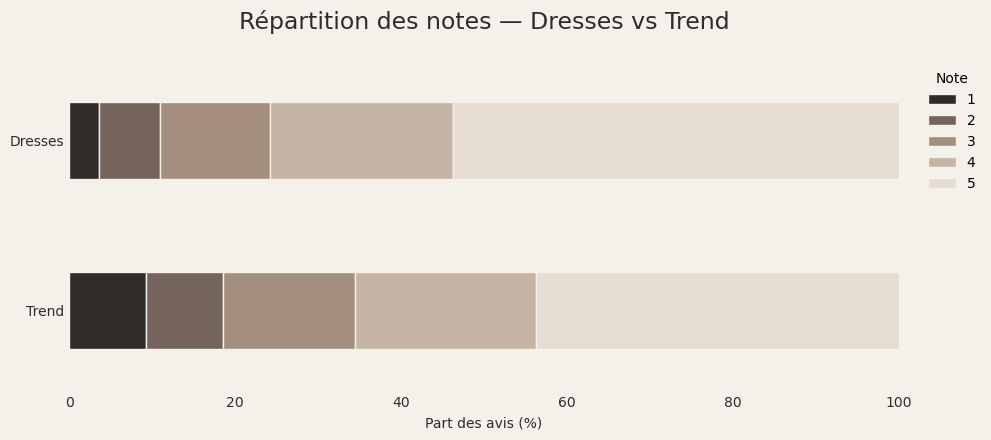

In [36]:
# Q01 — Step 2: Rating distribution visualization
# Beauté Cachée | Luxury Editorial Style

import matplotlib.pyplot as plt

brand_colors = [
    "#302B29",  # 1 star
    "#75645B",  # 2 stars
    "#A48E7E",  # 3 stars
    "#C5B4A5",  # 4 stars
    "#E6DCD2"   # 5 stars
]

fig, ax = plt.subplots(figsize=(10, 4.5))

fig.patch.set_facecolor("#F4F1EB")
ax.set_facecolor("#F4F1EB")

comparison.plot(
    kind="barh",
    stacked=True,
    color=brand_colors,
    ax=ax,
    width=0.45,
    edgecolor="#F4F1EB"
)

ax.set_title(
    "Répartition des notes — Dresses vs Trend",
    fontsize=17,
    color="#302B29",
    pad=22
)

ax.set_xlabel("Part des avis (%)", color="#302B29")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.invert_yaxis()

ax.legend(
    title="Note",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.tick_params(axis="both", colors="#302B29", length=0)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

# Étape 3 — Synthèse et interprétation métier

## Résultats clés

L'analyse met en évidence des différences de satisfaction entre les départements de produits.

Bottoms obtient la meilleure note moyenne (4,29/5) et le taux de recommandation le plus élevé (85,12 %).

Dresses présente une note moyenne de 4,15/5 sur 6 319 avis. La part des évaluations négatives (1–2 étoiles) atteint 10,91 %.

Trend enregistre la note moyenne la plus faible (3,82/5), avec 18,48 % d'avis négatifs et un taux de recommandation de 73,95 %.

## Interprétation métier

Le département Dresses constitue une priorité d'investigation en raison du volume important d'avis et d'un niveau de satisfaction inférieur à celui des départements les mieux évalués.

Le département Trend présente des signaux de satisfaction plus faibles. Toutefois, le nombre limité d'observations (119 avis) nécessite une interprétation prudente.

## Pistes d'investigation

Identifier les motifs récurrents d'insatisfaction dans les avis négatifs de Dresses et Trend.

Comparer les résultats au niveau des classes de produits (Class Name).

Examiner la relation entre les notes attribuées et les recommandations.

## Limite méthodologique

Les résultats reflètent les avis présents dans le jeu de données et ne peuvent pas être généralisés automatiquement à l'ensemble des clientes. Les causes d'insatisfaction restent à déterminer.

## Q02 — Recommandation des produits

**Question métier :** Comment le taux de recommandation varie-t-il selon les départements de produits ?

**Objectif :** Identifier les départements présentant les taux de recommandation les plus élevés et les plus faibles, puis examiner les différences observées.

**Indicateur :** Recommendation Rate (%) = moyenne de `Recommended IND` × 100.

**Méthode :** Comparaison des taux de recommandation et des volumes d'avis par département.

In [37]:
# Q02 — Step 1: Recommendation Rate by Department

recommendation_analysis = (
    department_analysis[
        ["Department Name", "Review_Count", "Recommendation_Rate"]
    ]
    .sort_values(
        by="Recommendation_Rate",
        ascending=False
    )
    .reset_index(drop=True)
)

display(recommendation_analysis)

,Department Name,Review_Count,Recommendation_Rate
0,Bottoms,3798,85.12
1,Intimate,1735,85.01
2,Jackets,1032,83.62
3,Tops,10468,81.52
4,Dresses,6319,80.82
5,Trend,119,73.95


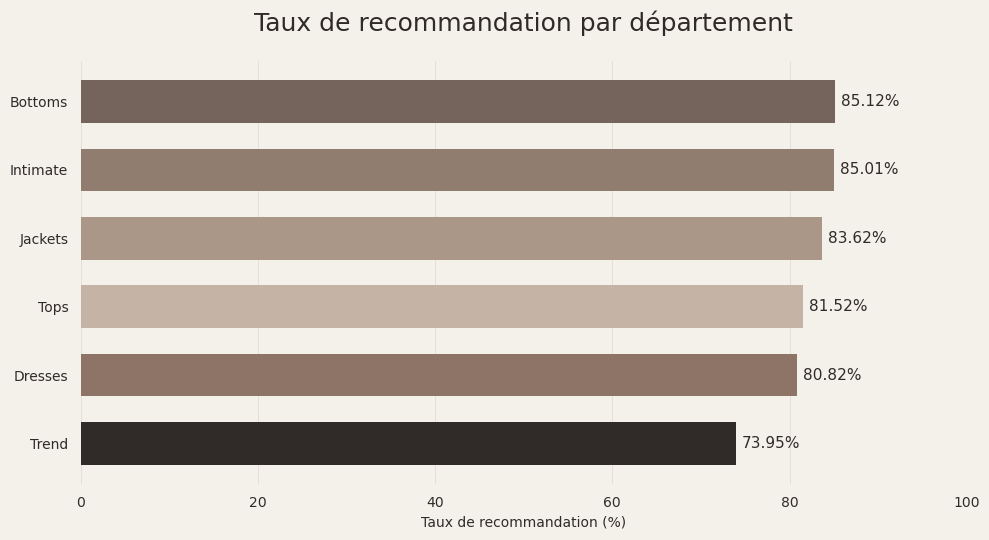

In [38]:
# Q02 — Step 2: Recommendation Rate by Department
# Beauté Cachée | Luxury Editorial Style

import matplotlib.pyplot as plt

department_colors = {
    "Bottoms": "#75645B",
    "Intimate": "#917D70",
    "Jackets": "#AA9788",
    "Tops": "#C5B4A5",
    "Dresses": "#8D7467",
    "Trend": "#302B29"
}

fig, ax = plt.subplots(figsize=(10, 5.5))

fig.patch.set_facecolor("#F4F1EB")
ax.set_facecolor("#F4F1EB")

colors = [
    department_colors[dept]
    for dept in recommendation_analysis["Department Name"]
]

bars = ax.barh(
    recommendation_analysis["Department Name"],
    recommendation_analysis["Recommendation_Rate"],
    color=colors,
    height=0.62
)

# Add percentage labels
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=11,
        color="#302B29"
    )

ax.set_xlim(0, 100)
ax.invert_yaxis()

ax.set_title(
    "Taux de recommandation par département",
    fontsize=18,
    color="#302B29",
    pad=22
)

ax.set_xlabel(
    "Taux de recommandation (%)",
    color="#302B29"
)

ax.tick_params(
    axis="both",
    colors="#302B29",
    length=0,
    pad=9
)

ax.grid(
    axis="x",
    color="#DAD1C9",
    alpha=0.55,
    linewidth=0.7
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

In [39]:
# Q02 — Step 3: Confidence intervals for recommendation rates

from statsmodels.stats.proportion import proportion_confint

recommendation_ci = (
    df_clean.dropna(subset=["Department Name", "Recommended IND"])
    .groupby("Department Name")["Recommended IND"]
    .agg(
        Review_Count="count",
        Recommended_Count="sum"
    )
    .reset_index()
)

recommendation_ci["Recommendation_Rate"] = (
    recommendation_ci["Recommended_Count"]
    / recommendation_ci["Review_Count"] * 100
)

# Wilson 95% confidence intervals
lower, upper = proportion_confint(
    count=recommendation_ci["Recommended_Count"],
    nobs=recommendation_ci["Review_Count"],
    alpha=0.05,
    method="wilson"
)

recommendation_ci["CI_Lower"] = lower * 100
recommendation_ci["CI_Upper"] = upper * 100

recommendation_ci = recommendation_ci.sort_values(
    "Recommendation_Rate",
    ascending=False
)

display(recommendation_ci.round(2))

,Department Name,Review_Count,Recommended_Count,Recommendation_Rate,CI_Lower,CI_Upper
0,Bottoms,3798,3233,85.12,83.96,86.22
2,Intimate,1735,1475,85.01,83.26,86.62
3,Jackets,1032,863,83.62,81.24,85.76
4,Tops,10468,8533,81.52,80.76,82.25
1,Dresses,6319,5107,80.82,79.83,81.77
5,Trend,119,88,73.95,65.40,81.00


### Étape 4 — Synthèse et interprétation métier

**Résultats clés**

- **Bottoms** présente le taux de recommandation le plus élevé : 85,12 % (IC à 95 % : 83,96–86,22 %).
- **Intimate** affiche un résultat très proche : 85,01 %.
- **Dresses** enregistre un taux de recommandation de 80,82 % sur 6 319 avis, avec un intervalle de confiance relativement étroit (79,83–81,77 %).
- **Trend** présente le taux le plus faible (73,95 %), mais son intervalle de confiance est nettement plus large (65,40–81,00 %), compte tenu du faible nombre d'avis (119).

**Interprétation métier**

Les départements Bottoms et Intimate présentent les meilleurs résultats observés en matière de recommandation.

Dresses constitue une piste d'investigation prioritaire en raison de son volume important d'avis et de son taux de recommandation inférieur à celui des départements les mieux évalués.

Trend présente des signaux moins favorables, mais les résultats doivent être interprétés avec prudence en raison de la taille limitée de l'échantillon.

**Pistes d'action**

- Approfondir l'analyse des motifs d'insatisfaction dans les départements Dresses et Trend.
- Examiner les classes de produits qui contribuent aux écarts observés.
- Étudier la relation entre les notes attribuées et la recommandation des produits.

**Limite méthodologique**

Les intervalles de confiance de Wilson reposent sur des hypothèses statistiques, notamment l'indépendance des observations. Les avis disponibles ne constituent pas nécessairement un échantillon représentatif de l'ensemble des clientes.

## Q03 — Cohérence entre évaluation et recommandation

**Question métier :** Dans quelle mesure les notes attribuées aux produits correspondent-elles aux recommandations des clientes ?

**Objectif :** Analyser la relation entre la note attribuée à un produit et la décision de le recommander, puis identifier les éventuelles divergences.

**Variables étudiées :**
- `Rating` : note de satisfaction de 1 à 5.
- `Recommended IND` : indicateur binaire de recommandation (1 = oui, 0 = non).

**Méthode :** Tableau croisé des notes et des recommandations, calcul du taux de recommandation par niveau de note et analyse des observations atypiques.

In [40]:
# Q03 — Step 1: Rating vs Recommendation

rating_recommendation = pd.crosstab(
    df_clean["Rating"],
    df_clean["Recommended IND"]
)

display(rating_recommendation)

Recommended IND,0,1
Rating,,
1,826,16
2,1471,94
3,1682,1189
4,168,4909
5,25,13105


In [41]:
# Q03 — Recommendation Rate by Rating

recommendation_by_rating = pd.crosstab(
    df_clean["Rating"],
    df_clean["Recommended IND"],
    normalize="index"
) * 100

display(recommendation_by_rating.round(2))

Recommended IND,0,1
Rating,,
1,98.10,1.90
2,93.99,6.01
3,58.59,41.41
4,3.31,96.69
5,0.19,99.81


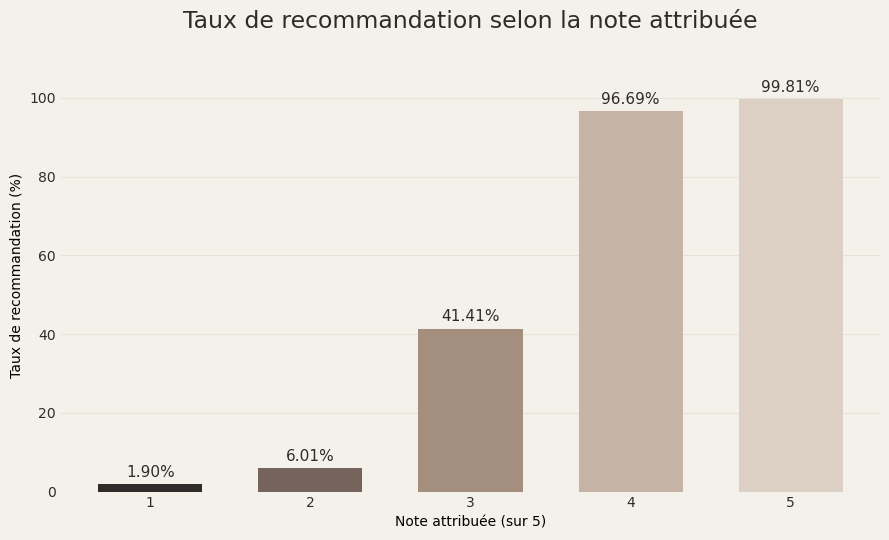

In [42]:
# Q03 — Step 2: Recommendation Rate by Rating
# Beauté Cachée | Luxury Editorial Style

import matplotlib.pyplot as plt

recommendation_rates = (
    recommendation_by_rating[1]
    .sort_index()
)

colors = [
    "#302B29",
    "#75645B",
    "#A48E7E",
    "#C5B4A5",
    "#DCCFC3"
]

fig, ax = plt.subplots(figsize=(9, 5.5))

fig.patch.set_facecolor("#F4F1EB")
ax.set_facecolor("#F4F1EB")

bars = ax.bar(
    recommendation_rates.index.astype(str),
    recommendation_rates.values,
    color=colors,
    width=0.65
)

# Percentage labels
for bar in bars:
    value = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1.8,
        f"{value:.2f}%",
        ha="center",
        fontsize=11,
        color="#302B29"
    )

ax.set_title(
    "Taux de recommandation selon la note attribuée",
    fontsize=17,
    color="#302B29",
    pad=22
)

ax.set_xlabel("Note attribuée (sur 5)")
ax.set_ylabel("Taux de recommandation (%)")
ax.set_ylim(0, 110)

ax.grid(
    axis="y",
    alpha=0.25,
    color="#C5B4A5"
)

ax.set_axisbelow(True)
ax.tick_params(length=0, colors="#302B29")

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

In [43]:
# Q03 — Step 3: Identify rating/recommendation inconsistencies

inconsistent_reviews = df_clean[
    (
        (df_clean["Rating"] <= 2) &
        (df_clean["Recommended IND"] == 1)
    )
    |
    (
        (df_clean["Rating"] >= 4) &
        (df_clean["Recommended IND"] == 0)
    )
]

print("Number of inconsistent reviews:", len(inconsistent_reviews))

display(
    inconsistent_reviews[
        [
            "Clothing ID",
            "Rating",
            "Recommended IND",
            "Title",
            "Review Text"
        ]
    ].head(10)
)

Number of inconsistent reviews: 303


,Clothing ID,Rating,Recommended IND,Title,Review Text
204,828,4,0,Too big,"I loved this top; it reminded me of one i have from retailer from circa 2008 in black and white; however, on this one, the chest area is too big, in both the 14 and 16, and i even found myself tugging downward on the fabric to keep it in place because the waist is elastic and also too big. i probably need a size 12, but then i fear it would be too short-waisted on me, for i am 5'10"". unfortunately, it is not for me. also, the sleeves are much bigger and flouncier than they appear in the photo on t"
403,902,2,1,NaN,"I got this top to wear with shorts as the color goes with a lot of different prints. the quality is excellent. this top runs very large, as in three (3) sizes too large. for the record i am a 34.25.35 and ordered my regular size the xs and this top makes me like i'm pregnant with twins. also, the layering looks nothing like it does on the model, it looks sloppy, unkept and a general. i think this would still be great for ladies who are bigger in the chest and waist, otherwise it just doesn't wor"
440,1083,4,0,Bunches up weirdly in the front,"I loved this dress as soon as i tried it on, but... it bunched up weird in the front around my hips. i ordered a second size 4, hoping that it would fit better. but same thing. if i tried to go to a size 6 it would be too big every where else. fyi - i'm 5'8"" 129lbs and i'm a runner. it's not like i have a huge backside or anything. my guess is sizing is off. i've tried another of his dresses and it fit perfectly."
503,948,2,1,Itchytown,"Is not a place i want to be, even if the style of a sweater is great. yes, this sweater is very cropped, but i think it&amp;#39;s definitely intended to be worn off the shoulder to drop the waist a bit. it&amp;#39;s the itchiness that makes it an immediate &amp;quot;no&amp;quot;, and that&amp;#39;s coming from someone who has serious fiber itch tolerance."
551,1078,2,1,NaN,"I loved this dress when i saw it. however the fit was way off. i am 5'7"" 120 lbs and the small was way too big from the waist down. when the xs arrived i was sure it would be perfect. unfortunately the waist hit way too high, above my rib cage and the dress was too short. it was as if it was a petite size. i was very disappointed as this is such a pretty, easy dress to just throw on for school. unfortunately neither size looked right on me and i had to return both. the material is also not the s"
829,895,2,1,Sent to me damaged,"I ordered the in the emerald green and it was sent to me with a dime size hole in the sleeve. i am very disappointed, because i love the sweater. by the time it arrived, it was sold out in my size. now, i cannot exchange it for one that is not damaged. if the sweater was not damaged, i would recommend this product."
837,886,4,0,NaN,"I ordered this in two colors, in my regular size. i washed and laid flat to dry....it shrunk like crazy. i held the one i washed up to the other unworn/unwashed one and it was at least two inches shorter. they may both be going back. i am so sad."
886,1086,4,0,Maybe one i got it's not right?,"Got the small petite. length is perfect, love the color, super comfy, very pretty. the problem is that you cannot wear a bra because under the armpits is so low that either shows your bra (a lot) or if u wear sans bra you may show your breasts (it's loose all around on top, so very easy to show everything. if i adjust the straps it works but then the waist goes up and it looks like i have a belly. i'm taking to a seamstress to see if she can take in under armpits, if not it's going back. i'm 5',"
899,1066,4,0,NaN,"I ordered these in my usual pilcro petite size 6. they were impossible to button, which is interesting 'cause i also ordered the pilcro wide leg chinos in the same size and they fit perfectly, as usual. but it ended up being ok because i don't care for the speckled, slightly rough material or the contrasting piping. back they go!"
943,154,4,0,"Pretty

In [44]:
# Q03 — Step 4: Quantify rating/recommendation divergences

low_rating_recommended = (
    (df_clean["Rating"] <= 2) &
    (df_clean["Recommended IND"] == 1)
)

high_rating_not_recommended = (
    (df_clean["Rating"] >= 4) &
    (df_clean["Recommended IND"] == 0)
)

print(
    "Low rating but recommended:",
    low_rating_recommended.sum()
)

print(
    "High rating but not recommended:",
    high_rating_not_recommended.sum()
)

print(
    "Total divergent reviews:",
    (low_rating_recommended | high_rating_not_recommended).sum()
)

print(
    "Share of all reviews (%):",
    round(
        (low_rating_recommended | high_rating_not_recommended).mean() * 100,
        2
    )
)

Low rating but recommended: 110
High rating but not recommended: 193
Total divergent reviews: 303
Share of all reviews (%): 1.29


### Étape 5 — Synthèse et interprétation métier

**Résultats clés**

L'analyse met en évidence une forte association entre la note attribuée au produit et la décision de le recommander.

- Le taux de recommandation passe de **1,90 % pour les notes de 1/5** à **99,81 % pour les notes de 5/5**.
- La progression la plus importante se situe entre les notes de 3 et 4 étoiles : **41,41 % contre 96,69 %**.
- **303 avis (1,29 %)** présentent une divergence selon les critères retenus :
  - 110 avis avec une note faible (1–2/5) mais une recommandation positive.
  - 193 avis avec une note élevée (4–5/5) mais sans recommandation.

**Interprétation métier**

Les notes et les recommandations sont fortement associées, mais ne traduisent pas toujours les mêmes dimensions de l'expérience client.

L'examen qualitatif de plusieurs avis divergents révèle notamment des problèmes de taille, de coupe, de confort, de qualité du produit ou de réception d'un article endommagé.

Ces observations suggèrent qu'une cliente peut apprécier certaines caractéristiques d'un produit tout en hésitant à le recommander, ou inversement.

**Pistes d'action**

- Approfondir l'analyse des motifs d'insatisfaction exprimés dans les commentaires.
- Examiner les problèmes de taille, de qualité et de conformité des produits.
- Utiliser conjointement `Rating` et `Recommended IND` dans le suivi de l'expérience client.

**Limites méthodologiques**

Les divergences sont définies ici comme une note de 1–2 avec recommandation, ou une note de 4–5 sans recommandation. Les notes de 3 ne sont pas classées comme divergentes.

L'analyse qualitative repose sur un nombre limité d'exemples et ne permet pas encore de mesurer la fréquence des différents problèmes.

**Conclusion**

L'utilisation combinée des évaluations et des recommandations permet de mieux comprendre l'expérience client qu'un indicateur de satisfaction isolé.

## Q04 — Segmentation des clientes par âge

**Question métier :** Comment les évaluations et les recommandations varient-elles selon les tranches d'âge ?

**Objectif :** Identifier les éventuelles différences de satisfaction et de recommandation entre les groupes d'âge.

**Variables étudiées :**
- `Age`
- `Rating`
- `Recommended IND`

**Méthode :** Création de six tranches d'âge, puis comparaison du nombre d'avis, de la note moyenne et du taux de recommandation par segment.

**Limite :** Les tranches d'âge sont définies pour les besoins de l'analyse. Elles ne représentent pas une segmentation CRM officielle.

In [45]:
# Q04 — Step 1: Create age groups

import pandas as pd

age_bins = [18, 25, 35, 45, 55, 65, float("inf")]

age_labels = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

df_clean["Age_Group"] = pd.cut(
    df_clean["Age"],
    bins=age_bins,
    labels=age_labels,
    right=False,
    include_lowest=True
)

# Check distribution
display(
    df_clean["Age_Group"]
    .value_counts(dropna=False)
    .sort_index()
)

print("Total observations:", len(df_clean))
print("Missing age groups:", df_clean["Age_Group"].isna().sum())

Age_Group
18-24     892
25-34    5175
35-44    7770
45-54    5110
55-64    3152
65+      1386
Name: count, dtype: int64

Total observations: 23485
Missing age groups: 0


In [46]:
# Q04 — Step 2: Customer satisfaction by age group

age_analysis = (
    df_clean.groupby("Age_Group", observed=True)
    .agg(
        Review_Count=("Rating", "count"),
        Average_Rating=("Rating", "mean"),
        Recommendation_Rate=("Recommended IND", "mean")
    )
    .reset_index()
)

# Convert recommendation rate to percentage
age_analysis["Recommendation_Rate"] *= 100

# Round KPI values
age_analysis = age_analysis.round(2)

display(age_analysis)

,Age_Group,Review_Count,Average_Rating,Recommendation_Rate
0,18-24,892,4.33,86.66
1,25-34,5175,4.14,80.02
2,35-44,7770,4.18,81.72
3,45-54,5110,4.17,82.07
4,55-64,3152,4.29,84.74
5,65+,1386,4.26,85.43


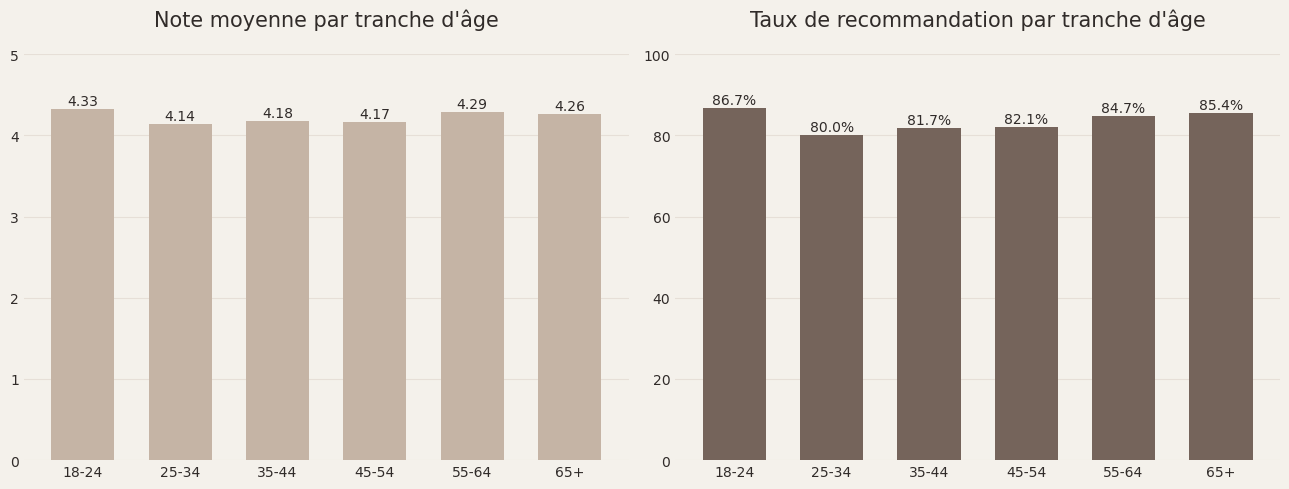

In [47]:
# Q04 — Step 3: Satisfaction and recommendation by age
# Beauté Cachée | Luxury Editorial Style

import matplotlib.pyplot as plt

ivory = "#F4F1EB"
charcoal = "#302B29"
taupe = "#C5B4A5"

age_groups = age_analysis["Age_Group"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

fig.patch.set_facecolor(ivory)

for ax in axes:
    ax.set_facecolor(ivory)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#DDD4CB", alpha=0.6)
    ax.tick_params(colors=charcoal, length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

# Average Rating
bars1 = axes[0].bar(
    age_groups,
    age_analysis["Average_Rating"],
    color=taupe,
    width=0.65
)

axes[0].set_title(
    "Note moyenne par tranche d'âge",
    color=charcoal,
    fontsize=15,
    pad=20
)

axes[0].set_ylim(0, 5)

for bar in bars1:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{bar.get_height():.2f}",
        ha="center",
        color=charcoal
    )

# Recommendation Rate
bars2 = axes[1].bar(
    age_groups,
    age_analysis["Recommendation_Rate"],
    color="#75645B",
    width=0.65
)

axes[1].set_title(
    "Taux de recommandation par tranche d'âge",
    color=charcoal,
    fontsize=15,
    pad=20
)

axes[1].set_ylim(0, 100)

for bar in bars2:
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center",
        color=charcoal
    )

plt.tight_layout()
plt.show()

In [48]:
# Q04 — Product department distribution by age group

age_department = pd.crosstab(
    df_clean["Age_Group"],
    df_clean["Department Name"],
    normalize="index"
) * 100

display(age_department.round(2))

Department Name,Bottoms,Dresses,Intimate,Jackets,Tops,Trend
Age_Group,,,,,,
18-24,14.59,30.64,8.98,4.71,40.40,0.67
25-34,15.76,29.47,9.34,4.58,40.56,0.29
35-44,16.77,27.92,7.28,3.95,43.49,0.59
45-54,16.71,25.39,6.84,4.07,46.43,0.57
55-64,16.31,24.40,5.11,4.98,48.73,0.48
65+,13.28,20.85,7.00,5.84,52.45,0.58


### Étape 4 — Synthèse et interprétation métier

#### Résultats clés

L'analyse des 23 485 avis met en évidence des différences de satisfaction et de recommandation selon les tranches d'âge.

- Les 18–24 ans présentent la note moyenne la plus élevée (4,33/5) et le meilleur taux de recommandation (86,66 %).
- Les 25–34 ans enregistrent les indicateurs les plus faibles : 4,14/5 et 80,02 % de recommandation.
- Les 55–64 ans et les 65 ans et plus affichent également des niveaux de satisfaction relativement élevés.
- La tranche des 35–44 ans représente le volume d'avis le plus important (7 770 observations).

#### Interprétation métier

Les résultats suggèrent une relation non linéaire entre l'âge et les indicateurs de satisfaction.

L'analyse complémentaire révèle également une évolution de la composition des avis par département :

- La part des avis Tops passe de 40,40 % chez les 18–24 ans à 52,45 % chez les 65 ans et plus.
- La part des avis Dresses diminue de 30,64 % à 20,85 % entre ces deux groupes.

Ces différences de composition peuvent influencer les résultats globaux de satisfaction, mais leur effet n'a pas encore été isolé.

#### Pistes d'investigation

- Comparer les évaluations des différentes tranches d'âge au sein d'un même département.
- Examiner les motifs d'insatisfaction de la tranche des 25–34 ans.
- Étudier les différences de besoins et d'attentes exprimées dans les commentaires.

#### Limites méthodologiques

Les résultats concernent les avis disponibles, et non l'ensemble des clientes ou des achats.

Les tranches d'âge constituent une segmentation analytique et ne correspondent pas à des segments CRM officiellement définis.

Les différences observées sont descriptives et ne permettent pas d'établir un lien causal entre l'âge et la satisfaction.

#### Conclusion

L'âge constitue une dimension pertinente pour approfondir l'analyse de l'expérience client, notamment lorsqu'il est croisé avec les catégories de produits et les motifs de satisfaction ou d'insatisfaction.

## Q05 — Analyse des commentaires clients

**Question métier :** Quels sont les principaux motifs de satisfaction et d'insatisfaction exprimés dans les avis clients ?

**Objectif :** Identifier les thèmes récurrents dans les commentaires afin de mieux comprendre les attentes, les points de satisfaction et les difficultés rencontrées par les clientes.

**Variables étudiées :**
- `Review Text`
- `Rating`
- `Recommended IND`
- `Department Name`
- `Class Name`

**Méthode :** Préparation des textes, analyse exploratoire des commentaires, identification et quantification des thèmes récurrents, puis comparaison par département.

**Résultat attendu :** Identifier les principaux irritants de l'expérience client et proposer des pistes d'amélioration opérationnelles.

In [49]:
# Q05 — Step 1: Text data availability

total_reviews = len(df_clean)

valid_text = (
    df_clean["Review Text"].notna()
    & df_clean["Review Text"].str.strip().ne("")
)

reviews_with_text = valid_text.sum()
reviews_without_text = total_reviews - reviews_with_text

text_coverage = reviews_with_text / total_reviews * 100

print("Total reviews:", total_reviews)
print("Reviews with text:", reviews_with_text)
print("Reviews without text:", reviews_without_text)
print("Text coverage (%):", round(text_coverage, 2))

Total reviews: 23485
Reviews with text: 22640
Reviews without text: 845
Text coverage (%): 96.4


In [50]:
# Q05 — Step 2: Create text analysis dataset

df_text = df_clean.loc[valid_text].copy()

# Verify text dataset
print("Text dataset rows:", len(df_text))
print("Missing review texts:", df_text["Review Text"].isna().sum())

display(
    df_text[
        ["Rating", "Recommended IND", "Review Text"]
    ].head(5)
)

Text dataset rows: 22640
Missing review texts: 0


,Rating,Recommended IND,Review Text
0,4,1,Absolutely wonderful - silky and sexy and comfortable
1,5,1,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite. i bought a petite and am 5'8"". i love the length on me- hits just a little below the knee. would definitely be a true midi on someone who is truly petite."
2,3,0,"I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall, the top half was comfortable and fit nicely, but the bottom half had a very tight under layer and several somewhat cheap (net) over layers. imo, a major design flaw was the net over layer sewn directly into the zipper - it c"
3,5,1,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great compliments!"
4,5,1,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings and it is sleeveless so it pairs well with any cardigan. love this shirt!!!


In [51]:
# Q05 — Step 3: Review length analysis

df_text["Word_Count"] = (
    df_text["Review Text"]
    .str.split()
    .str.len()
)

display(df_text["Word_Count"].describe())

count    22640.000000
mean        60.197482
std         28.534986
min          2.000000
25%         36.000000
50%         59.000000
75%         88.000000
max        115.000000
Name: Word_Count, dtype: float64

In [52]:
# Q05 — Review length by rating

review_length_analysis = (
    df_text.groupby("Rating")
    .agg(
        Review_Count=("Word_Count", "count"),
        Average_Words=("Word_Count", "mean"),
        Median_Words=("Word_Count", "median")
    )
    .reset_index()
    .round(2)
)

display(review_length_analysis)

,Rating,Review_Count,Average_Words,Median_Words
0,1,821,58.63,57.0
1,2,1549,62.06,62.0
2,3,2823,64.22,64.0
3,4,4908,63.32,64.0
4,5,12539,57.94,56.0


In [53]:
# Q05 — Text preprocessing

import re
import html

def clean_review_text(text):
    # Decode HTML entities
    text = html.unescape(text)

    # Convert to lowercase
    text = text.lower()

    # Remove special characters, keep letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Create a new cleaned text column
df_text["Review_Text_Clean"] = (
    df_text["Review Text"].apply(clean_review_text)
)

# Compare original and cleaned texts
display(
    df_text[
        ["Review Text", "Review_Text_Clean"]
    ].head(5)
)

,Review Text,Review_Text_Clean
0,Absolutely wonderful - silky and sexy and comfortable,absolutely wonderful silky and sexy and comfortable
1,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite. i bought a petite and am 5'8"". i love the length on me- hits just a little below the knee. would definitely be a true midi on someone who is truly petite.",love this dress it s sooo pretty i happened to find it in a store and i m glad i did bc i never would have ordered it online bc it s petite i bought a petite and am i love the length on me hits just a little below the knee would definitely be a true midi on someone who is truly petite
2,"I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall, the top half was comfortable and fit nicely, but the bottom half had a very tight under layer and several somewhat cheap (net) over layers. imo, a major design flaw was the net over layer sewn directly into the zipper - it c",i had such high hopes for this dress and really wanted it to work for me i initially ordered the petite small my usual size but i found this to be outrageously small so small in fact that i could not zip it up i reordered it in petite medium which was just ok overall the top half was comfortable and fit nicely but the bottom half had a very tight under layer and several somewhat cheap net over layers imo a major design flaw was the net over layer sewn directly into the zipper it c
3,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great compliments!",i love love love this jumpsuit it s fun flirty and fabulous every time i wear it i get nothing but great compliments
4,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings and it is sleeveless so it pairs well with any cardigan. love this shirt!!!,this shirt is very flattering to all due to the adjustable front tie it is the perfect length to wear with leggings and it is sleeveless so it pairs well with any cardigan love this shirt


In [54]:
# Q05 — Improved text preprocessing

import re
import html

def clean_review_text(text):

    # Decode HTML entities (including double-encoded entities)
    for _ in range(2):
        text = html.unescape(text)

    # Convert to lowercase
    text = text.lower()

    # Normalize common contractions
    text = re.sub(r"n['’]t\b", " not", text)
    text = re.sub(r"['’]re\b", " are", text)
    text = re.sub(r"['’]ve\b", " have", text)
    text = re.sub(r"['’]ll\b", " will", text)
    text = re.sub(r"['’]m\b", " am", text)
    text = re.sub(r"['’]s\b", " is", text)

    # Keep letters and numbers
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Update cleaned text column
df_text["Review_Text_Clean"] = (
    df_text["Review Text"].apply(clean_review_text)
)

display(
    df_text[["Review Text", "Review_Text_Clean"]].head(5)
)

,Review Text,Review_Text_Clean
0,Absolutely wonderful - silky and sexy and comfortable,absolutely wonderful silky and sexy and comfortable
1,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite. i bought a petite and am 5'8"". i love the length on me- hits just a little below the knee. would definitely be a true midi on someone who is truly petite.",love this dress it is sooo pretty i happened to find it in a store and i am glad i did bc i never would have ordered it online bc it is petite i bought a petite and am 5 8 i love the length on me hits just a little below the knee would definitely be a true midi on someone who is truly petite
2,"I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall, the top half was comfortable and fit nicely, but the bottom half had a very tight under layer and several somewhat cheap (net) over layers. imo, a major design flaw was the net over layer sewn directly into the zipper - it c",i had such high hopes for this dress and really wanted it to work for me i initially ordered the petite small my usual size but i found this to be outrageously small so small in fact that i could not zip it up i reordered it in petite medium which was just ok overall the top half was comfortable and fit nicely but the bottom half had a very tight under layer and several somewhat cheap net over layers imo a major design flaw was the net over layer sewn directly into the zipper it c
3,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great compliments!",i love love love this jumpsuit it is fun flirty and fabulous every time i wear it i get nothing but great compliments
4,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings and it is sleeveless so it pairs well with any cardigan. love this shirt!!!,this shirt is very flattering to all due to the adjustable front tie it is the perfect length to wear with leggings and it is sleeveless so it pairs well with any cardigan love this shirt


In [55]:
# Q05 — Step 3: Unigram frequency analysis

from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 1),
    max_features=20
)

word_matrix = vectorizer.fit_transform(
    df_text["Review_Text_Clean"]
)

word_counts = word_matrix.sum(axis=0).A1

top_words = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": word_counts
}).sort_values(
    by="Frequency",
    ascending=False
).reset_index(drop=True)

display(top_words)

,Word,Frequency
0,dress,10567
1,love,8948
2,size,8771
3,fit,7324
4,like,7148
5,wear,6439
6,great,6117
7,just,5608
8,fabric,4798
9,small,4729


In [56]:
# Q05 — Step 3.2: Bigram frequency analysis

from sklearn.feature_extraction.text import CountVectorizer

bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    max_features=30,
    min_df=5
)

bigram_matrix = bigram_vectorizer.fit_transform(
    df_text["Review_Text_Clean"]
)

bigram_counts = bigram_matrix.sum(axis=0).A1

top_bigrams = pd.DataFrame({
    "Bigram": bigram_vectorizer.get_feature_names_out(),
    "Frequency": bigram_counts
}).sort_values(
    by="Frequency",
    ascending=False
).reset_index(drop=True)

display(top_bigrams.head(20))

,Bigram,Frequency
0,it is,12666
1,in the,7169
2,and the,5612
3,this dress,4758
4,on the,4338
5,of the,3932
6,and it,3723
7,it was,3287
8,this top,2939
9,this is,2773


In [57]:
# Q05 — Step 3.3: Meaningful bigram analysis

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.feature_extraction.text import CountVectorizer

# Keep important words for interpreting reviews
important_words = {
    "not", "no", "never", "too",
    "very", "small", "large"
}

# Define custom stop words
custom_stop_words = (
    set(ENGLISH_STOP_WORDS) - important_words
)

# Extract bigrams
meaningful_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    min_df=5
)

X = meaningful_vectorizer.fit_transform(
    df_text["Review_Text_Clean"]
)

features = meaningful_vectorizer.get_feature_names_out()
frequencies = X.sum(axis=0).A1

meaningful_bigrams = pd.DataFrame({
    "Bigram": features,
    "Frequency": frequencies
})

# Filter bigrams made entirely of stop words
meaningful_bigrams = meaningful_bigrams[
    meaningful_bigrams["Bigram"].apply(
        lambda phrase: any(
            word not in custom_stop_words
            for word in phrase.split()
        )
    )
]

meaningful_bigrams = (
    meaningful_bigrams
    .sort_values("Frequency", ascending=False)
    .head(30)
    .reset_index(drop=True)
)

display(meaningful_bigrams.head(20))

,Bigram,Frequency
0,this dress,4758
1,is very,2739
2,the fabric,2655
3,love the,2641
4,did not,2500
5,love this,2333
6,to wear,2267
7,the dress,2180
8,is not,2144
9,do not,2142


### Étape 3 — Synthèse de l'analyse lexicale exploratoire

L'analyse des unigrammes et des bigrammes met en évidence la fréquence élevée des termes liés aux produits, notamment `size`, `fit`, `fabric` et `dress`.

Cependant, les expressions les plus fréquentes restent majoritairement descriptives ou grammaticales et ne permettent pas d'identifier directement les motifs d'insatisfaction.

**Conclusion méthodologique :** La fréquence des mots ne suffit pas à déterminer leur tonalité positive ou négative. Une analyse contextualisée des commentaires est nécessaire.

**Décision :** Poursuivre l'analyse en distinguant les avis selon leur note, puis identifier et quantifier les thèmes récurrents dans les commentaires.

### Étape 4 — Comparaison des avis selon leur tonalité

**Objectif :** Comparer le vocabulaire des avis faiblement et fortement notés afin d'identifier les thèmes associés à la satisfaction et à l'insatisfaction.

**Segmentation :**
- Avis négatifs : notes de 1 à 2
- Avis mitigés : note de 3
- Avis positifs : notes de 4 à 5

**Limite méthodologique :** Cette classification repose sur la note attribuée et non sur une analyse automatique du sentiment exprimé dans le texte.

In [58]:
# Q05 — Step 4.1: Classify reviews by rating

import numpy as np

df_text["Review_Group"] = np.select(
    [
        df_text["Rating"].isin([1, 2]),
        df_text["Rating"] == 3,
        df_text["Rating"].isin([4, 5])
    ],
    ["Negative", "Mixed", "Positive"],
    default="Unknown"
)

display(
    df_text["Review_Group"].value_counts()
)

Review_Group
Positive    17447
Mixed        2823
Negative     2370
Name: count, dtype: int64

In [59]:
# Q05 — Step 4.2: Compare expressions in negative and positive reviews

from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Select negative and positive reviews
df_compare = df_text[
    df_text["Review_Group"].isin(["Negative", "Positive"])
].copy()

# Extract bigrams and trigrams
vectorizer = CountVectorizer(
    ngram_range=(2, 3),
    min_df=15,
    binary=True
)

X = vectorizer.fit_transform(df_compare["Review_Text_Clean"])

# Identify groups
negative_mask = (
    df_compare["Review_Group"] == "Negative"
).to_numpy()

positive_mask = (
    df_compare["Review_Group"] == "Positive"
).to_numpy()

# Percentage of reviews containing each expression
negative_rate = X[negative_mask].mean(axis=0).A1 * 100
positive_rate = X[positive_mask].mean(axis=0).A1 * 100

expression_analysis = pd.DataFrame({
    "Expression": vectorizer.get_feature_names_out(),
    "Negative_Rate": negative_rate,
    "Positive_Rate": positive_rate
})

# Difference in percentage points
expression_analysis["Difference_pp"] = (
    expression_analysis["Negative_Rate"]
    - expression_analysis["Positive_Rate"]
)

# Keep expressions appearing in at least 2% of negative reviews
negative_expressions = (
    expression_analysis[
        expression_analysis["Negative_Rate"] >= 2
    ]
    .sort_values("Difference_pp", ascending=False)
    .head(20)
    .round(2)
)

display(negative_expressions)

,Expression,Negative_Rate,Positive_Rate,Difference_pp
6699,it was,20.68,9.79,10.89
3202,did not,15.82,7.73,8.10
8766,of the,20.63,13.23,7.40
14393,wanted to,7.81,1.09,6.72
2469,but the,13.08,6.52,6.56
5494,in the,30.30,24.10,6.19
14541,was so,7.26,1.26,6.00
4625,going back,6.08,0.33,5.74
12223,the model,9.41,4.11,5.30
13551,to love,5.65,0.47,5.18


In [60]:
# Q05 — Step 4.3: Inspect expressions in context

expressions = ["going back", "not flattering"]

for expression in expressions:
    print(f"\n--- Expression: {expression} ---")

    examples = df_text[
        (df_text["Review_Group"] == "Negative")
        & df_text["Review_Text_Clean"].str.contains(
            expression,
            regex=False
        )
    ]

    display(
        examples[
            ["Rating", "Department Name", "Review Text"]
        ].head(5)
    )


--- Expression: going back ---


,Rating,Department Name,Review Text
33,2,Tops,"I ordered this 3 months ago, and it finally came off back order. a huge disappointment. the fit wasn&#39;t so much the issue for me. the quality of the wool is subpar. someone else mentioned a &quot;felted wool&quot;...i guess, is that what you call it? it does literally feel like felt! super thin, itchy, doesn&#39;t drape very well, and feels cheap (made in china). i got it on sale, but still not worth what i paid. definitely going back."
96,1,Tops,"I usually wear a medium and bought a small. it fit ok, but had no shape and was not flattering. i love baby doll dresses and tops, but this was a tent. my daughter saw me try it on and said ""that's a piece of tablecloth."" it's going back."
114,2,Dresses,"The design/shape of the dress are quite flattering, flirty and feminine. but.... there is no way that the dress i received is new. the color is a faded washed out red and there are black stains all over the belt area. there is no tag... the fabric looks droopy and laundered and is not crisp, stiff or new. i am very disappointed by the quality of the item that i received. undoubtedly this one is going back.\n\ndear retailer - please make sure that you do not send pre-owend clothing articles to"
191,2,Tops,"I was minimally torn over whether to return this but ultimately it's going back because the knit is just too thin. i thought it would be cozy and be of normal sweater weight but it's not. and because it's so light, the swing effect doesn't really come off. nothing special."
286,2,Tops,"Like the other reviewer said this top is extremely wide and boxy. it must be pinned in the picture online. it's very frustrating when they do that. thank goodness i didn't pay for shipping! for reference, i'm 5'2 and 135 pounds and bought the xxs, it's going back for sure. i'm trying to lose baby weight, not trying to look pregnant!"



--- Expression: not flattering ---


,Rating,Department Name,Review Text
85,1,Tops,"I was really hoping to like this, but it did not look the way it does on the model, at least not on me. the sharkbite hem is much more pronounced and looser. the one in the photo looks like it was pinned back. i am 5'8"" and usually wear a medium or large. i got a medium and there was a lot more material on the bottom half than the photo shows. it made me look bigger and was not flattering. material has a nice weave but it's thin and delicate. i bought the (holly) deep olive and the blue. colors"
88,2,Tops,"Really cute piece, but it's huge. i ordered an xxs petite and it was unfortunately extremely wide and not flattering. returning."
96,1,Tops,"I usually wear a medium and bought a small. it fit ok, but had no shape and was not flattering. i love baby doll dresses and tops, but this was a tent. my daughter saw me try it on and said ""that's a piece of tablecloth."" it's going back."
288,2,Tops,"I wanted to love this sweatshirt, but alas, it is going back. upon opening and unfolding, the first thing i noticed: the dots and not solid. they are sort of distressed looking, with parts of them missing. secondly, it doesn't have a lot of structure. it's soft and kind of floppy but in a weird way. it's just not flattering on me. it looks more like a pajama top than something i would wear out of the house. for reference, i ordered the 3, and i'm usually a 10/12 in tops."
579,2,Tops,"I was really excited about this top since i have others from retailer that are similar in styling. unfortunately, it just didn't work out. i am petite with a short torso and ordered my usual size and it was way too short in the front. the top was also boxy and didn't sit right. it just wasn't flattering. cute top on the hanger, but just not on me."


### Étape 4.3 — Synthèse de l'analyse qualitative

L'examen de dix avis négatifs contenant les expressions
« going back » et « not flattering » a permis d'identifier
plusieurs motifs potentiels d'insatisfaction :

- Fit & Sizing
- Material & Comfort
- Product Quality
- Product Condition
- Product Representation

La catégorie « Product Representation » a émergé lors
de cette analyse, notamment à travers des commentaires
signalant un écart entre les photographies en ligne
et l'apparence réelle des produits.

L'expression « going back » semble principalement
indiquer une intention de retour, et non une cause
autonome d'insatisfaction.

**Limite :** Cette analyse qualitative repose sur
dix exemples sélectionnés à partir de deux expressions.
Les thèmes restent exploratoires et leur fréquence
dans l'ensemble des avis négatifs doit être vérifiée.

**Prochaine étape :** Construire et valider une
classification thématique fondée sur des règles
explicites.

### Étape 5 — Classification des motifs d'insatisfaction

**Objectif :** Quantifier les principaux problèmes évoqués dans les avis négatifs.

**Méthode :** Classification exploratoire fondée sur des expressions et des règles explicites (rule-based classification).

**Population :** Avis textuels avec `Rating` de 1 à 2 étoiles.

**Principe :** Un même avis peut mentionner plusieurs problèmes. Les catégories ne sont donc pas mutuellement exclusives.

In [61]:
# Q05 — Step 5.1: Identify customer pain points

import re
import pandas as pd

# Select negative reviews
df_negative = df_text[
    df_text["Review_Group"] == "Negative"
].copy()

# Preliminary issue detection rules
pain_point_patterns = {
    "Fit & Sizing": (
        r"\btoo (?:big|small|large|short|long|tight|loose)\b"
        r"|\bruns? (?:big|small|large)\b"
        r"|\bnot flattering\b"
        r"|\bpoor fit\b"
        r"|\bboxy\b"
        r"|\bdid not fit\b"
    ),

    "Material & Comfort": (
        r"\bitchy\b"
        r"|\bscratchy\b"
        r"|\buncomfortable\b"
        r"|\brough fabric\b"
        r"|\bthin fabric\b"
        r"|\bcheap material\b"
    ),

    "Product Quality": (
        r"\bpoor quality\b"
        r"|\bcheap quality\b"
        r"|\bshrunk\b"
        r"|\bshrink\b"
        r"|\bfell apart\b"
        r"|\bpoorly made\b"
        r"|\bbad stitching\b"
    ),

    "Product Condition": (
        r"\bdamaged\b"
        r"|\bstain(?:ed|s)?\b"
        r"|\bhole\b"
        r"|\bmissing tag\b"
        r"|\barrived dirty\b"
    ),

    "Product Representation": (
        r"\bnot as pictured\b"
        r"|\bdifferent from (?:the )?(?:photo|picture)\b"
        r"|\blooks? nothing like\b"
        r"|\bnot (?:like|as shown in) the (?:photo|picture)\b"
        r"|\bmisleading photo\b"
    )
}

# Detect each theme
for theme, pattern in pain_point_patterns.items():
    df_negative[theme] = (
        df_negative["Review_Text_Clean"]
        .str.contains(pattern, regex=True, na=False)
    )

# Count reviews mentioning each theme
pain_point_analysis = pd.DataFrame({
    "Theme": list(pain_point_patterns.keys()),
    "Review_Count": [
        int(df_negative[theme].sum())
        for theme in pain_point_patterns
    ]
})

pain_point_analysis["Rate_Percent"] = (
    pain_point_analysis["Review_Count"]
    / len(df_negative) * 100
)

pain_point_analysis = (
    pain_point_analysis
    .sort_values("Review_Count", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

display(pain_point_analysis)

,Theme,Review_Count,Rate_Percent
0,Fit & Sizing,565,23.84
1,Material & Comfort,104,4.39
2,Product Quality,87,3.67
3,Product Condition,63,2.66
4,Product Representation,25,1.05


In [62]:
# Q05 — Step 5.2: Classification coverage

theme_columns = list(pain_point_patterns.keys())

# Number of detected themes per review
df_negative["Theme_Count"] = (
    df_negative[theme_columns].sum(axis=1)
)

total_negative = len(df_negative)

classified = (df_negative["Theme_Count"] >= 1).sum()
unclassified = (df_negative["Theme_Count"] == 0).sum()
multiple_themes = (df_negative["Theme_Count"] >= 2).sum()

print("Total negative reviews:", total_negative)
print("Reviews with at least one theme:", classified)
print("Reviews without detected theme:", unclassified)
print("Reviews with multiple themes:", multiple_themes)

print(
    "Classification coverage (%):",
    round(classified / total_negative * 100, 2)
)

Total negative reviews: 2370
Reviews with at least one theme: 788
Reviews without detected theme: 1582
Reviews with multiple themes: 55
Classification coverage (%): 33.25


In [63]:
# Q05 — Step 5.3: Manual validation sample

theme_columns = list(pain_point_patterns.keys())

# Three examples per detected theme
for theme in theme_columns:
    print(f"\n--- {theme} ---")

    examples = df_negative.loc[
        df_negative[theme],
        ["Rating", "Review Text"]
    ].sample(
        n=min(3, int(df_negative[theme].sum())),
        random_state=42
    )

    display(examples)

# Five examples without detected themes
print("\n--- Unclassified reviews ---")

unclassified_examples = df_negative.loc[
    df_negative["Theme_Count"] == 0,
    ["Rating", "Review Text"]
].sample(n=5, random_state=42)

display(unclassified_examples)


--- Fit & Sizing ---


,Rating,Review Text
22417,2,"Hi, when i received this top i tried it on, looked in the mirror and packed it up for a return. the quality is excellent but it just too boxy. fits nothing like it appears on the model."
21963,2,"I ordered this in a 4 (34b, 140lbs., 5'8"") because it looked like it would run big, and it definitely does! the 4 fit comfortably but the cut of this dress made me look about 10 lbs. heavier than i am. i am pear-shaped and this dress made me look very bottom heavy, so i returned it. that said, the material is gorgeous!, as it is the perfect weight and the colors are much more striking and complementary in person. if i had a straight(er) silhouette and a larger bust, this dress would have been a"
10186,1,"This dress is not flattering. the slip is very small and short and the dress is big and billowy. like the other reviewer said, its more like a tablecloth that you stick your head through. it was really hard to figure out how to cinch in the waist but it didn't help regardless. the length is not accurate either. i would say it's a pretty short dress (mid thigh) but that probably depends on the person. it also makes you look very horizontal. i was really excited about this dress but it's getting r"



--- Material & Comfort ---


,Rating,Review Text
7735,2,"I was so bummed when this came in...the colors and print are beautiful, but the neck is super itchy because of an elastic/ruffle combo. there is also a liner which is a nice touch, but it's significantly shorter than the top layer which drove me nuts. definitely going back."
14989,2,I loved the way it looks on. fit tts. only problem for me was it was so itchy. there is that small amt. of wool in it. if you have any problem with wool this may not work for you
14894,1,The neckline is very tight and itchy. the arm holes are deeply cut. the length is not as long in person as it is on the model in the picture. it's short-waisted. it's too bad because the embroidery is very pretty.



--- Product Quality ---


...

,Rating,Review Text
22200,2,"I have had this shirt for a little over a month. i've wore it maybe 3-5 times and there is a small hole in the middle of the sleeve on my shoulder. it's not even on a seam, so i can't fix it. i expect much better quality from retailer. don't buy this. the quality is very disappointing. which is really unfortunate because this is a very nice fitting shirt and goes well with pencil skirts."
20909,1,"I really loved the way this shirt looked on me. it's forgiving and flattering, and really lightweight. the fabric, however, couldn't even withstand half a day's wear without snagging 3 times and developing a hole right in the center. i have no idea how this happened, as i wasn't wearing or near anything that could have pulled at it. \r\n\r\nsuch a shame. this could have been a staple wardrobe piece for me."
114,2,"The design/shape of the dress are quite flattering, flirty and feminine. but.... there is no way that the dress i received is new. the color is a faded washed out red and there are black stains all over the belt area. there is no tag... the fabric looks droopy and laundered and is not crisp, stiff or new. i am very disappointed by the quality of the item that i received. undoubtedly this one is going back.\n\ndear retailer - please make sure that you do not send pre-owend clothing articles to"



--- Product Representation ---


,Rating,Review Text
10147,1,"I've been shopping at retailer since 2007, and floreat used to be my favorite designer, but for the past year or more, floreat mostly misses the mark. this blouse looks nothing like it does on the model. \r\n1. it is long on her, not so in real life. this is probably the worst part about this blouse. if it were not for this, i might try on a size m and give it another chance.\r\n2. it runs very large. i usually take a l or xl. i think i would need a m in this, as mentioned above.\r\n3. in the picture, t"
16545,1,"Hahaha..this dress is hilarious! it looks nothing like the image! i am usually a 0/xs, and 4 was the smallest size available, so i ordered it. when i opened it, it felt like 10 lbs of fabric. i thought maybe i ordered a size way too big, until i could barely squeeze into the top of the dress. once i looked in the mirror, i almost fell over laughing. the rest of the dress is huge. i don't believe this dress would be flattering on anyone."
403,2,"I got this top to wear with shorts as the color goes with a lot of different prints. the quality is excellent. this top runs very large, as in three (3) sizes too large. for the record i am a 34.25.35 and ordered my regular size the xs and this top makes me like i'm pregnant with twins. also, the layering looks nothing like it does on the model, it looks sloppy, unkept and a general. i think this would still be great for ladies who are bigger in the chest and waist, otherwise it just doesn't wor"



--- Unclassified reviews ---


,Rating,Review Text
16658,2,"I ordered this online, and when i opened the package, i was impressed with the quality of the material and stitching for this top. it is much nicer than a basic t-shirt.\r\n\r\nwhen i tried this on, the band of stitching that was supposed to go beneath my chest was sitting on top of my cleavage! also, the overall length is listed as 27"" long, but i think that is the back of the shirt. the front of the shirt is very short on me (i'm 5'10""), hitting well above my hip bones.\r\n\r\nif only this was much, m"
11929,2,"I was really excited to get this top in the mail; unlike other reviewers, i didn't find that the top fit small, but i thought that the tight fit across the shoulders and chest didn't look good with the billow-y torso of the top. i think this top would be flattering on really thin girls, but i'm very tall and broad shouldered, so it didn't look as good on me."
17363,2,So sad becuase i like the design. i would not recomend the lack to anyone that does not live and work and shop in a completely immaculate environment. i wore this to work the day after purchasing and within three hours i honestly looked like i had slept in this sweater for three monthe straight. i had to take the sweater off and work in a t-shirt. \r\nthe marigold color may be better than the black abut showing lint but something intrinsic to the fabric really attracts lint like nothing i have eve
8059,1,The dress arrived wrinkled so i washed it and pressed it. it looked beautiful until i sat down. the entire dress was wrinkled and it looked terrible all day. can't wear this again.
7796,1,Love the softness and the length. the color was perfect. but you have be be a very skinny almost boney person for you to not show imperfections to your body. the fabric is not thick enough and does not have the give to over shadow normal imperfections. will be returning the sweater.


In [64]:
# Q05 — Step 5.4: Refine pain point detection rules

# Extend existing patterns with observed expressions
pain_point_patterns["Fit & Sizing"] += (
    r"|\btight fit\b"
    r"|\btoo wide\b"
    r"|\btoo boxy\b"
    r"|\bshort waisted\b"
    r"|\bdid not look good on me\b"
    r"|\bdoes not fit\b"
)

pain_point_patterns["Material & Comfort"] += (
    r"|\battracts? lint\b"
    r"|\bwrinkles? easily\b"
    r"|\bwrinkled\b"
    r"|\bnot thick enough\b"
)

# Narrow Product Condition to delivery/receipt problems
pain_point_patterns["Product Condition"] = (
    r"\barrived damaged\b"
    r"|\breceived damaged\b"
    r"|\barrived (?:with|in)\b.{0,35}\b(?:hole|stain|damage)\b"
    r"|\breceived\b.{0,35}\b(?:hole|stain|damage)\b"
    r"|\bmissing tag\b"
    r"|\bblack stains\b"
    r"|\barrived dirty\b"
)

# Recalculate all five themes
for theme, pattern in pain_point_patterns.items():
    df_negative[theme] = (
        df_negative["Review_Text_Clean"]
        .str.contains(pattern, regex=True, na=False)
    )

theme_columns = list(pain_point_patterns.keys())

pain_point_analysis = pd.DataFrame({
    "Theme": theme_columns,
    "Review_Count": [
        int(df_negative[theme].sum())
        for theme in theme_columns
    ]
})

pain_point_analysis["Rate_Percent"] = (
    pain_point_analysis["Review_Count"]
    / len(df_negative) * 100
)

pain_point_analysis = (
    pain_point_analysis
    .sort_values("Review_Count", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

df_negative["Theme_Count"] = (
    df_negative[theme_columns].sum(axis=1)
)

display(pain_point_analysis)

print(
    "Classification coverage (%):",
    round((df_negative["Theme_Count"] > 0).mean() * 100, 2)
)

,Theme,Review_Count,Rate_Percent
0,Fit & Sizing,596,25.15
1,Material & Comfort,129,5.44
2,Product Quality,87,3.67
3,Product Representation,25,1.05
4,Product Condition,6,0.25


Classification coverage (%): 33.42


### Étape 6 — Synthèse et interprétation métier

#### Résultats clés

L'analyse porte sur 22 640 commentaires clients, dont 2 370 avis négatifs (notes de 1 à 2 étoiles).

Une classification exploratoire fondée sur des expressions prédéfinies a permis d'identifier cinq thèmes :

| Thème | Nombre d'avis | Part des avis négatifs |
|---|---:|---:|
| Fit & Sizing | 596 | 25,15 % |
| Material & Comfort | 129 | 5,44 % |
| Product Quality | 87 | 3,67 % |
| Product Representation | 25 | 1,05 % |
| Product Condition | 6 | 0,25 % |

Les problèmes de taille et de coupe constituent le thème le plus fréquemment détecté.

Le taux de couverture de la classification atteint 33,42 % des avis négatifs.

#### Interprétation métier

Les résultats suggèrent que la taille et la coupe des vêtements représentent un axe prioritaire d'investigation pour l'amélioration de l'expérience client.

L'analyse qualitative a également mis en évidence des problèmes liés aux matériaux, à la qualité des produits et aux écarts entre la présentation en ligne et le produit reçu.

#### Recommandations opérationnelles

1. **Size & Fit Guidance** — Améliorer les guides de tailles, les informations sur la coupe et les conseils d'ajustement sur les fiches produits.

2. **Product Information** — Renforcer la précision des descriptions des matières et des photographies des produits.

3. **Quality Monitoring** — Suivre les retours clients relatifs à la qualité, à la durabilité et à l'état des articles reçus.

#### Limites méthodologiques

La classification repose sur des règles de détection et non sur une analyse exhaustive des motifs d'insatisfaction.

Les catégories ne sont pas mutuellement exclusives : un avis peut mentionner plusieurs problèmes.

Le taux de couverture de 33,42 % ne permet pas de généraliser les fréquences observées à l'ensemble des insatisfactions.

Les résultats servent à identifier des signaux prioritaires et des pistes d'investigation, et non à établir un diagnostic exhaustif.

#### Conclusion

L'analyse des commentaires complète les indicateurs quantitatifs de satisfaction en apportant des éléments de compréhension sur les difficultés rencontrées par les clientes.

# Synthèse — Analyse du Dataset 1 : Customer Reviews

**Projet :** Beauté Cachée — Customer Experience & CRM Intelligence  
**Source :** Women's E-Commerce Clothing Reviews  
**Statut :** Analyse terminée

## 1. Objectifs de l'analyse

L'objectif de cette première phase était d'exploiter les avis clients afin d'évaluer la satisfaction, d'identifier les différences entre catégories de produits et segments d'âge, et de détecter les principaux motifs d'insatisfaction.

L'analyse visait à répondre à cinq questions métier :

- **Q01 — Satisfaction par département :** Quels départements obtiennent les meilleures et les moins bonnes évaluations ?
- **Q02 — Recommandation :** Comment le taux de recommandation varie-t-il selon les départements ?
- **Q03 — Cohérence des indicateurs :** Dans quelle mesure les notes et les recommandations sont-elles associées ?
- **Q04 — Segmentation par âge :** Comment la satisfaction varie-t-elle selon les tranches d'âge ?
- **Q05 — Analyse des commentaires :** Quels problèmes récurrents apparaissent dans les avis négatifs ?

## 2. Préparation et validation des données

Le jeu de données initial contenait **23 486 observations**.

Les contrôles ont porté sur :

- Les valeurs manquantes et les types de variables.
- Les doublons exacts et les doublons potentiels.
- La validité des variables `Rating`, `Recommended IND`, `Age` et `Positive Feedback Count`.
- La cohérence des catégories `Division Name`, `Department Name` et `Class Name`.

**Décisions principales :**

- Une observation strictement dupliquée a été supprimée de la copie analytique.
- Les avis sans commentaire textuel ont été conservés pour les analyses quantitatives.
- Les 14 observations sans classification produit ont été conservées pour les KPI globaux.
- Les valeurs inhabituelles mais plausibles ont été conservées.

**Résultat : 23 485 observations après nettoyage.**

Le jeu de données source a été préservé.

## 3. KPI et méthodes d'analyse

| KPI / indicateur | Méthode de calcul ou de vérification |
|---|---|
| Review Count | Nombre d'observations exploitables |
| Average Rating | Moyenne de `Rating` |
| Recommendation Rate | Moyenne de `Recommended IND` × 100 |
| Positive Rating Rate | Part des notes de 4 à 5 étoiles |
| Negative Rating Rate | Part des notes de 1 à 2 étoiles |
| Rating Distribution | Distribution des notes avec `value_counts()` et `pd.crosstab()` |
| Customer Pain Points Rate | Part des avis négatifs contenant des expressions associées à chaque thème |

Les analyses ont été réalisées en Python avec **pandas**, à l'aide d'opérations de regroupement (`groupby`), d'agrégation (`agg`) et de tableaux croisés (`crosstab`).

Des visualisations ont été produites avec Matplotlib. Les taux de recommandation par département ont également été examinés à l'aide d'intervalles de confiance de Wilson à 95 %, sous les hypothèses statistiques correspondantes.

## 4. Principaux résultats métier

### Q01 — Satisfaction par département

Le département **Bottoms** obtient la meilleure note moyenne (4,29/5) et le meilleur taux de recommandation (85,12 %).

Le département **Trend** présente les résultats les plus faibles (3,82/5 ; 73,95 % de recommandation), mais avec seulement 119 avis.

Le département **Dresses**, avec 6 319 avis et une note moyenne de 4,15/5, représente une priorité d'investigation en raison de son volume important de retours clients.

### Q02 — Recommandation

Les taux de recommandation varient entre **73,95 % et 85,12 %** selon les départements.

Le classement des départements selon ce taux correspond à celui observé pour la note moyenne.

L'analyse des intervalles de confiance a été utilisée pour examiner l'incertitude liée aux différences de volumes d'avis.

### Q03 — Évaluation et recommandation

Les notes et les recommandations présentent une forte association descriptive.

Le taux de recommandation passe de **41,41 % pour les notes de 3 étoiles** à **96,69 % pour les notes de 4 étoiles**.

Toutefois, **303 avis (1,29 %)** présentent une divergence selon les critères retenus : note faible avec recommandation ou note élevée sans recommandation.

Ces observations montrent l'intérêt de suivre conjointement les deux indicateurs.

### Q04 — Segmentation par âge

Les **18–24 ans** présentent les indicateurs les plus élevés : 4,33/5 et 86,66 % de recommandation.

Les **25–34 ans** affichent les résultats les plus faibles : 4,14/5 et 80,02 %.

La composition des avis varie également selon l'âge. La part consacrée aux produits Tops augmente avec l'âge, tandis que celle des produits Dresses diminue.

Ces différences restent descriptives et ne démontrent pas d'effet causal de l'âge.

### Q05 — Analyse des commentaires

Sur 23 485 observations, **22 640 comportent un commentaire exploitable**, soit 96,4 %.

L'analyse a combiné :

- Prétraitement des textes.
- Analyse exploratoire des unigrammes et bigrammes.
- Comparaison du vocabulaire des avis positifs et négatifs.
- Lecture qualitative de commentaires.
- Classification exploratoire par règles et expressions régulières.
- Vérification manuelle d'exemples.

Cinq thèmes de problèmes ont été étudiés.

| Thème | Avis négatifs détectés | Taux |
|---|---:|---:|
| Fit & Sizing | 596 | 25,15 % |
| Material & Comfort | 129 | 5,44 % |
| Product Quality | 87 | 3,67 % |
| Product Representation | 25 | 1,05 % |
| Product Condition | 6 | 0,25 % |

**Fit & Sizing** constitue le thème le plus fréquemment détecté parmi les catégories étudiées.

La couverture de la classification atteint **33,42 %** des 2 370 avis négatifs textuels. Les résultats représentent donc des fréquences de détection selon les règles définies, et non une mesure exhaustive des motifs d'insatisfaction.

## 5. Recommandations métier préliminaires

**Priorité 1 — Améliorer les informations de taille et de coupe**

Clarifier les guides de tailles, les indications sur la coupe des vêtements et les conseils d'ajustement sur les fiches produits.

**Priorité 2 — Renforcer la transparence de l'information produit**

Améliorer la précision des photographies, descriptions de matières et caractéristiques des articles afin de limiter les écarts entre attentes et expérience réelle.

**Priorité 3 — Structurer le suivi des problèmes de qualité**

Suivre les signalements relatifs aux matières, à la durabilité et à l'état des produits pour orienter les actions qualité.

Ces recommandations sont des pistes d'action à valider par des données opérationnelles complémentaires.

## 6. Limites méthodologiques

Le jeu de données contient des avis, et non l'ensemble des transactions ou des clientes du distributeur.

Les observations ne permettent pas d'identifier de manière fiable les clientes uniques.

La classification textuelle est exploratoire et ne capture pas l'ensemble des formulations possibles.

Enfin, ce dataset de commentaires réels n'est pas relié individuellement à la future base Sales & CRM synthétique.

## Conclusion

Cette première phase a permis de transformer des données d'avis clients en indicateurs de satisfaction, analyses comparatives et premières recommandations métier.

Elle constitue le volet **Customer Voice** du projet Beauté Cachée.

**Prochaine phase :** Analyse des données Sales & CRM synthétiques afin d'étudier la performance commerciale, les comportements d'achat et les indicateurs opérationnels de la relation client.